# Experiment 9 – Association Rule Mining using Apriori (Python)
**Dataset:** Food_Delivery_Customer_Churn.csv (500 records, 11 attributes)

**Aim:** Find frequent itemsets and association rules from the categorical attributes with the Apriori algorithm (mlxtend).

In [1]:
import glob
import pandas as pd
import matplotlib.pyplot as plt
from mlxtend.frequent_patterns import apriori, association_rules

# Works in Google Colab (/content) and locally (CSV in the same folder)
matches = glob.glob('/content/Food_Delivery_Customer_Churn*.csv') + glob.glob('Food_Delivery_Customer_Churn*.csv')
if not matches:
    raise FileNotFoundError('Place Food_Delivery_Customer_Churn.csv next to this notebook (or upload it in Colab).')
df = pd.read_csv(matches[0])
print('Dataset loaded:', matches[0])
print('Shape:', df.shape)
print('\nFirst 3 records (transposed):')
print(df.head(3).T.to_string())

Dataset loaded: Food_Delivery_Customer_Churn.csv
Shape: (500, 11)

First 3 records (transposed):
                              0         1        2
Age                          56        46       32
City                      Thane    Mumbai     Pune
Subscription_Type          Free      Free     Free
Orders_Per_Month              2         8       13
Average_Order_Value         151       738      793
Average_Delivery_Time        36        42       21
Discount_Usage               39        13       34
Favorite_Category        Indian   Chinese   Indian
Device                  Android       Web      iOS
Tenure_Months                 4        11       31
Churn                  Retained  Retained  Churned


## Step 1 – Select categorical attributes and one-hot encode (each `attribute=value` becomes an item)

In [2]:
cat_cols = ['City', 'Subscription_Type', 'Favorite_Category', 'Device', 'Churn']
basket = pd.get_dummies(df[cat_cols].astype(str), prefix_sep='=').astype(bool)
print('Basket shape (transactions x items):', basket.shape)
print('\nItems:')
for col in basket.columns:
    print(f'  {col:32s} {int(basket[col].sum()):4d} transactions')

Basket shape (transactions x items): (500, 16)

Items:
  City=Mumbai                       145 transactions
  City=Navi Mumbai                  108 transactions
  City=Pune                         125 transactions
  City=Thane                        122 transactions
  Subscription_Type=Free            311 transactions
  Subscription_Type=Premium         189 transactions
  Favorite_Category=Burgers         104 transactions
  Favorite_Category=Chinese          86 transactions
  Favorite_Category=Indian          112 transactions
  Favorite_Category=Mexican         102 transactions
  Favorite_Category=Pizza            96 transactions
  Device=Android                    171 transactions
  Device=Web                        164 transactions
  Device=iOS                        165 transactions
  Churn=Churned                     191 transactions
  Churn=Retained                    309 transactions


## Step 2 – Frequent itemsets (minimum support = 0.10)

In [3]:
frequent_itemsets = apriori(basket, min_support=0.10, use_colnames=True)
frequent_itemsets['length'] = frequent_itemsets['itemsets'].apply(len)
frequent_itemsets = frequent_itemsets.sort_values('support', ascending=False).reset_index(drop=True)

def names(s):
    return ', '.join(sorted(s))

print('Total frequent itemsets:', len(frequent_itemsets))
print(frequent_itemsets['length'].value_counts().sort_index().rename('count').to_string())
print('\nTop 15 frequent itemsets by support:')
top15 = frequent_itemsets.head(15).copy()
top15['itemsets'] = top15['itemsets'].apply(names)
print(top15[['itemsets', 'support', 'length']].to_string(index=False))

Total frequent itemsets: 61
length
1    16
2    39
3     6

Top 15 frequent itemsets by support:
                                 itemsets  support  length
                   Subscription_Type=Free    0.622       1
                           Churn=Retained    0.618       1
                            Churn=Churned    0.382       1
                Subscription_Type=Premium    0.378       1
   Churn=Retained, Subscription_Type=Free    0.360       2
                           Device=Android    0.342       1
                               Device=iOS    0.330       1
                               Device=Web    0.328       1
                              City=Mumbai    0.290       1
    Churn=Churned, Subscription_Type=Free    0.262       2
Churn=Retained, Subscription_Type=Premium    0.258       2
                                City=Pune    0.250       1
                               City=Thane    0.244       1
                 Favorite_Category=Indian    0.224       1
               Chu

## Step 3 – Association rules (minimum confidence = 0.60)

In [4]:
rules = association_rules(frequent_itemsets, metric='confidence', min_threshold=0.60)
rules = rules.sort_values(['lift', 'confidence'], ascending=False).reset_index(drop=True)

def show(r):
    t = r[['antecedents', 'consequents', 'support', 'confidence', 'lift']].copy()
    t['antecedents'] = t['antecedents'].apply(names)
    t['consequents'] = t['consequents'].apply(names)
    return t.round(3).to_string(index=False)

print('Total rules:', len(rules))
print('Lift range:', round(rules['lift'].min(), 3), 'to', round(rules['lift'].max(), 3))
print('Rules with lift < 1:', int((rules['lift'] < 1).sum()))
print('\nTop 10 rules by lift:')
print(show(rules.head(10)))

Total rules: 25
Lift range: 0.978 to 1.179
Rules with lift < 1: 5

Top 10 rules by lift:
                              antecedents            consequents  support  confidence  lift
Device=Android, Subscription_Type=Premium         Churn=Retained    0.102       0.729 1.179
                Churn=Churned, Device=Web Subscription_Type=Free    0.106       0.726 1.167
                Subscription_Type=Premium         Churn=Retained    0.258       0.683 1.104
                            Churn=Churned Subscription_Type=Free    0.262       0.686 1.103
       Device=iOS, Subscription_Type=Free         Churn=Retained    0.140       0.680 1.100
                               Device=iOS         Churn=Retained    0.222       0.673 1.089
                                City=Pune Subscription_Type=Free    0.164       0.656 1.055
                               Device=Web Subscription_Type=Free    0.214       0.652 1.049
                 Favorite_Category=Indian Subscription_Type=Free    0.144       0.6

## Step 4 – Rules with Churn as the consequent

In [5]:
churn_rules = rules[rules['consequents'].apply(lambda s: any(i.startswith('Churn=') for i in s))]
print('Rules predicting Churn status:', len(churn_rules))
print(show(churn_rules))

Rules predicting Churn status: 13
                              antecedents    consequents  support  confidence  lift
Device=Android, Subscription_Type=Premium Churn=Retained    0.102       0.729 1.179
                Subscription_Type=Premium Churn=Retained    0.258       0.683 1.104
       Device=iOS, Subscription_Type=Free Churn=Retained    0.140       0.680 1.100
                               Device=iOS Churn=Retained    0.222       0.673 1.089
                Favorite_Category=Mexican Churn=Retained    0.130       0.637 1.031
                                City=Pune Churn=Retained    0.158       0.632 1.023
                              City=Mumbai Churn=Retained    0.182       0.628 1.016
                           Device=Android Churn=Retained    0.214       0.626 1.013
                  Favorite_Category=Pizza Churn=Retained    0.120       0.625 1.011
                               City=Thane Churn=Retained    0.152       0.623 1.008
                 Favorite_Category=Indian 

## Step 5 – Visualizations and export

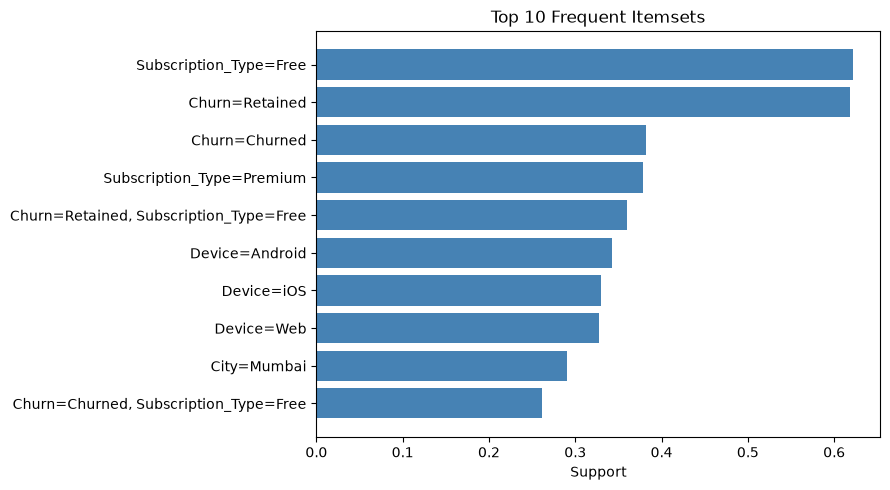

In [6]:
top = frequent_itemsets.head(10).copy()
top['label'] = top['itemsets'].apply(names)
plt.figure(figsize=(9, 5))
plt.barh(top['label'][::-1], top['support'][::-1], color='steelblue')
plt.xlabel('Support'); plt.title('Top 10 Frequent Itemsets')
plt.tight_layout(); plt.savefig('frequent_itemsets_graph.png', dpi=150); plt.show()

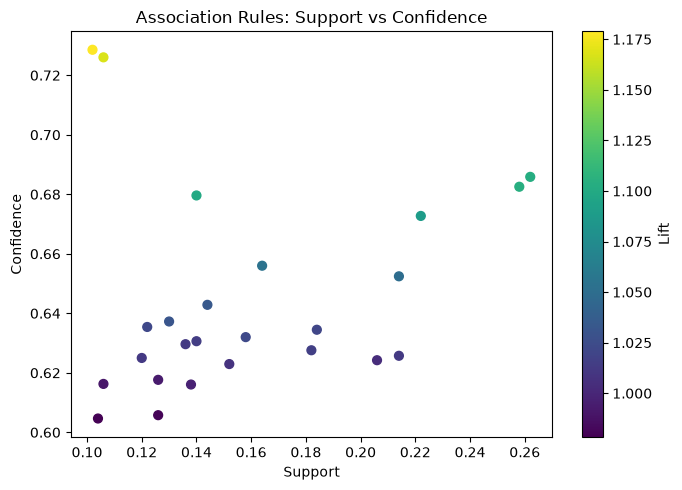

In [7]:
plt.figure(figsize=(7, 5))
sc = plt.scatter(rules['support'], rules['confidence'], c=rules['lift'], cmap='viridis', s=40)
plt.colorbar(sc, label='Lift'); plt.xlabel('Support'); plt.ylabel('Confidence')
plt.title('Association Rules: Support vs Confidence'); plt.tight_layout()
plt.savefig('Experiment9_Graphs.png', dpi=150); plt.show()

In [8]:
fi = frequent_itemsets.copy(); fi['itemsets'] = fi['itemsets'].apply(names)
fi.to_csv('frequent_itemsets.csv', index=False)
r = rules.copy()
for col in ['antecedents', 'consequents']:
    r[col] = r[col].apply(names)
r.to_csv('association_rules.csv', index=False)
print('Exported frequent_itemsets.csv and association_rules.csv')

Exported frequent_itemsets.csv and association_rules.csv
